## Late delivery Prediction

### Business Context 
An online retailer ships orders through several shipping modes and markets. Late deliveries hurt customer satisfaction and force reactive support work. Logistics can only intervene (upgrade the shipping mode, prioritize the order in the warehouse, warn the customer) if it knows at order time which orders are likely to be late.

### Problem statement
Given the information available when an order is placed, estimate the probability that it will be delivered late, and flag the highest-risk orders so logistics can intervene before shipping. 

### ML formulation 
- *Task* : Binary classification 
- *Traget* : late_delivery (late:1, on time or early : 0)
- *Prediction time* : the moment the order is placed 
- *unit of the prediction* : One order , meaning each Order get a Late_delivery_score 
- *Population* : All orders except shipping cancelled since they were never shipped . 

### Feature rules 
The model will only be trained on the information available at Order time , to prevent data leakage 

we will use data related to order , shippement , products , Customer and Geo 

*Forbidden (leakage)* : Days for shipping (real), Delivery Status, shipping date (DateOrders), Order Status 


In [121]:
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 
import numpy as np 
import warnings 
warnings.filterwarnings("ignore")

#sns.set_style("white")
plt.style.use("ggplot")
pd.set_option("display.max_columns", None)

### 01-Importing the data :

In [122]:
df = pd.read_csv("../Data/DataCoSupplyChainDataset.csv",encoding="latin-1")

### 02-Exploring the Data

In [123]:
df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,1/13/2018 11:45,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,1/13/2018 11:24,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


### first we need to inspect the granilarity of the data to see what each transaction means :
- we need to see if each transaction represents and order or order item 
- we need to check if which orders are delivred or and which are canceled 

In [124]:
# checking if we have duplicated Order Id 
df['Order Id'].duplicated().sum()

np.int64(114767)

In [125]:
# inspecting the duplicated Orders and checking if the items ordered share the same Order ID 
df[['Order Id','Product Name']].sort_values(by='Order Id',ascending=True).head(20)

,Order Id,Product Name
33833,1,Diamondback Women's Serene Classic Comfort Bi
87884,2,Nike Men's CJ Elite 2 TD Football Cleat
109322,2,Nike Men's Dri-FIT Victory Golf Polo
77011,2,Pelican Sunstream 100 Kayak
114915,4,O'Brien Men's Neoprene Life Vest
96131,4,Perfect Fitness Perfect Rip Deck
95938,4,Nike Men's Dri-FIT Victory Golf Polo
63764,4,Team Golf New England Patriots Putter Grip
114914,5,O'Brien Men's Neoprene Life Vest
20695,5,Diamondback Women's Serene Classic Comfort Bi


from the table above we can see that each item Ordered is stored as a transaction associated with a  Master Order ID , so each transaction is a unique Order Item not full Order 

In [126]:
Orders = df.groupby('Order Id')['Delivery Status'].first().reset_index()
print(f'we have {Orders.shape[0]} Full Order')
print(f'and {df.shape[0]} Item Order')

we have 65752 Full Order
and 180519 Item Order


In [127]:
# exploring the delivery status 
print("Delivery status rates %")
(Orders['Delivery Status'].value_counts(normalize=True))*100

Delivery status rates %


Delivery Status
Late delivery        54.824188
Advance shipping     23.006144
Shipping on time     17.827595
Shipping canceled     4.342073
Name: proportion, dtype: float64

The result shows that the business has a significant rate of late deliveries where more that half of the Orders were delivered after the scheduled date  , however 23% of the Orders were delivered on advance  , and 18% on time , meaning that only about 41% meet or beat the promised date, cancellation rate is 4% which relatively small at least in term of orders .

In [128]:
df.columns

Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Benefit per order', 'Sales per customer', 'Delivery Status',
       'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City',
       'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id',
       'Customer Lname', 'Customer Password', 'Customer Segment',
       'Customer State', 'Customer Street', 'Customer Zipcode',
       'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market',
       'Order City', 'Order Country', 'Order Customer Id',
       'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id',
       'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id',
       'Order Item Product Price', 'Order Item Profit Ratio',
       'Order Item Quantity', 'Sales', 'Order Item Total',
       'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status',
       'Order Zipcode', 'Product Card Id', 'Product Category Id',
       'Product De

In [129]:
customer_dim = [col for col in df.columns if col.startswith("Customer")]
order_dim = [col for col in df.columns if col.startswith("Order")]
product_dim = [col for col in df.columns if col.startswith("Product")]

In [130]:
customer_dim

['Customer City',
 'Customer Country',
 'Customer Email',
 'Customer Fname',
 'Customer Id',
 'Customer Lname',
 'Customer Password',
 'Customer Segment',
 'Customer State',
 'Customer Street',
 'Customer Zipcode']

In [131]:
order_dim

['Order City',
 'Order Country',
 'Order Customer Id',
 'Order Id',
 'Order Item Cardprod Id',
 'Order Item Discount',
 'Order Item Discount Rate',
 'Order Item Id',
 'Order Item Product Price',
 'Order Item Profit Ratio',
 'Order Item Quantity',
 'Order Item Total',
 'Order Profit Per Order',
 'Order Region',
 'Order State',
 'Order Status',
 'Order Zipcode']

In [132]:
product_dim

['Product Card Id',
 'Product Category Id',
 'Product Description',
 'Product Image',
 'Product Name',
 'Product Price',
 'Product Status']

### 03-Data Quality:

<Axes: >

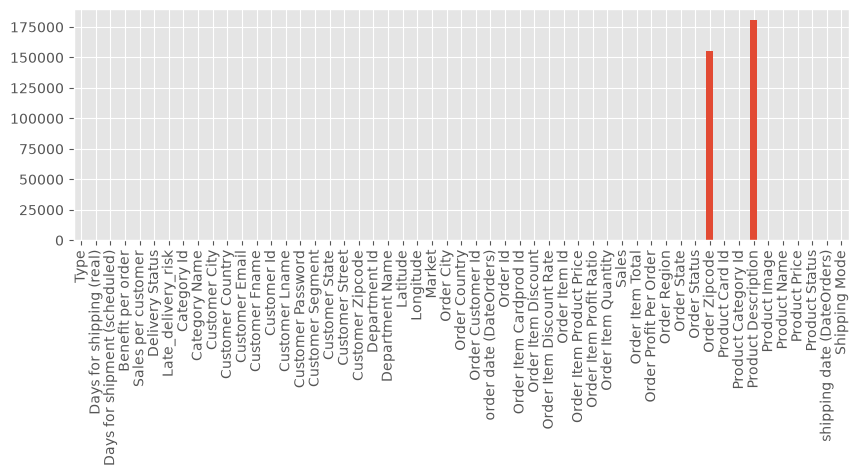

In [133]:
df.isna().sum().plot(kind="bar",figsize=(10,3))

<Axes: >

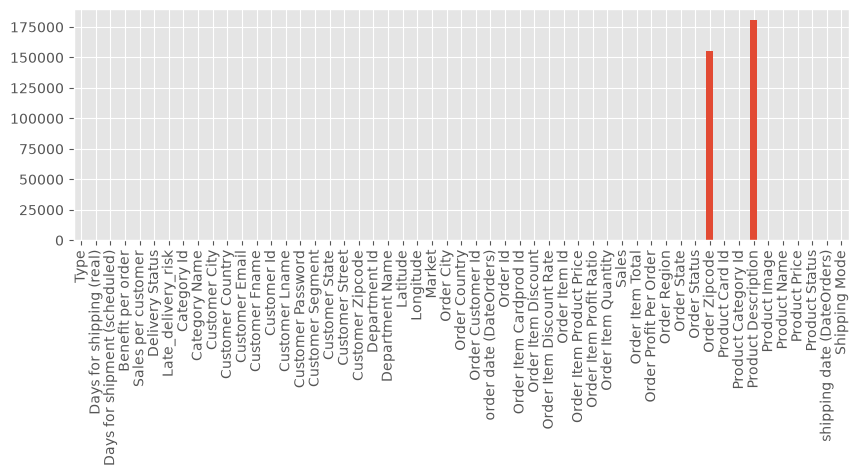

In [134]:
df.isnull().sum().plot(kind="bar",figsize=(10,3))

In [135]:
df.duplicated().sum()

np.int64(0)

Data Quality : 
- Only Two columns have missing values , those columns are only products and Order meta data 
- the rest of the  columns are clean 
- the data has no duplicated rows 

### 04-Data Selection

For this project we need to only select the features that are related to the delivery process , and since the data is transaction oriented meaning each transaction is an Order item , so we need to keep columns related to delivry , and feature enginner new fetures likes order amount , profit amount , number of products  , datetime features , and also check the cardinality of categorical features such as Order state , Order City ,also store informations . 


In [136]:
df.columns

Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Benefit per order', 'Sales per customer', 'Delivery Status',
       'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City',
       'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id',
       'Customer Lname', 'Customer Password', 'Customer Segment',
       'Customer State', 'Customer Street', 'Customer Zipcode',
       'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market',
       'Order City', 'Order Country', 'Order Customer Id',
       'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id',
       'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id',
       'Order Item Product Price', 'Order Item Profit Ratio',
       'Order Item Quantity', 'Sales', 'Order Item Total',
       'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status',
       'Order Zipcode', 'Product Card Id', 'Product Category Id',
       'Product De

In [143]:
# Creating the Orders dataframe 
columns_keep = ['Type', 'Days for shipping (real)',
        'Days for shipment (scheduled)', 'Delivery Status',
       'Late_delivery_risk',  'Customer Segment', 'Latitude', 'Longitude', 'Market',
       'Order City', 'Order Country', 'order date (DateOrders)', 'Order Id',
        'Order Region', 'Order State', 'shipping date (DateOrders)', 'Shipping Mode']

# first let exclude the None relevante columns 
Orders = df[columns_keep].groupby('Order Id').first().reset_index()
Orders.shape

(65752, 17)

In [145]:
Orders["Delivery Status"].value_counts()

Delivery Status
Late delivery        36048
Advance shipping     15127
Shipping on time     11722
Shipping canceled     2855
Name: count, dtype: int64

In [ ]:
Orders = Orders[Orders["Delivery Status"] != "Shipping canceled"].copy()

TypeError: bad operand type for unary ~: 'str'

In [138]:
# Add order-level aggregated features
new_features = df.groupby("Order Id").agg(
    Total_sales=("Order Item Total", "sum"),
    Total_discount=('Order Item Discount',"sum"),
    Profit_Order=("Order Profit Per Order", "sum"),
    count=("Order Id", "count"),
    num_items=("Order Item Quantity", "sum")
).reset_index()
new_features


,Order Id,Total_sales,Total_discount,Profit_Order,count,num_items
0,1,239.979996,60.000000,88.790001,1,1
1,2,529.380005,50.600000,195.900002,3,7
2,4,620.870014,78.980000,124.090000,4,14
3,5,987.070007,142.789999,390.089995,5,10
4,7,525.520004,54.400000,203.929998,3,7
...,...,...,...,...,...,...
65747,77200,161.869995,53.959999,-107.959999,1,1
65748,77201,172.660004,43.160000,-126.559998,1,1
65749,77202,314.640015,13.110000,91.250000,1,1
65750,77203,10.910000,0.630000,1.530000,1,1


In [139]:
Orders.columns

Index(['Order Id', 'Type', 'Days for shipping (real)',
       'Days for shipment (scheduled)', 'Delivery Status',
       'Late_delivery_risk', 'Customer Segment', 'Department Id',
       'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City',
       'Order Country', 'order date (DateOrders)', 'Order Item Discount',
       'Order Item Total', 'Order Profit Per Order', 'Order Region',
       'Order State', 'shipping date (DateOrders)', 'Shipping Mode'],
      dtype='str')

In [140]:
Orders = Orders.merge(new_features,on="Order Id",how="left") 

In [141]:
Orders.drop(
    ['Order Item Discount','Order Item Total', 'Order Profit Per Order','Department Id','Department Name']
    ,axis=1,inplace=True)

In [142]:
Orders

,Order Id,Type,Days for shipping (real),Days for shipment (scheduled),Delivery Status,Late_delivery_risk,Customer Segment,Latitude,Longitude,Market,Order City,Order Country,order date (DateOrders),Order Region,Order State,shipping date (DateOrders),Shipping Mode,Total_sales,Total_discount,Profit_Order,count,num_items
0,1,CASH,2,4,Advance shipping,0,Consumer,35.776661,-81.362625,LATAM,Mexico City,México,1/1/2015 0:00,Central America,Distrito Federal,1/3/2015 0:00,Standard Class,239.979996,60.000000,88.790001,1,1
1,2,PAYMENT,3,4,Advance shipping,0,Consumer,41.832722,-87.980484,LATAM,Dos Quebradas,Colombia,1/1/2015 0:21,South America,Risaralda,1/4/2015 0:21,Standard Class,529.380005,50.600000,195.900002,3,7
2,4,CASH,5,4,Late delivery,1,Home Office,29.520010,-98.637413,LATAM,Dos Quebradas,Colombia,1/1/2015 1:03,South America,Risaralda,1/6/2015 1:03,Standard Class,620.870014,78.980000,124.090000,4,14
3,5,DEBIT,6,4,Late delivery,1,Consumer,18.234238,-66.370605,LATAM,Dos Quebradas,Colombia,1/1/2015 1:24,South America,Risaralda,1/7/2015 1:24,Standard Class,987.070007,142.789999,390.089995,5,10
4,7,DEBIT,3,2,Late delivery,1,Consumer,25.888525,-80.172943,LATAM,São Paulo,Brasil,1/1/2015 2:06,South America,São Paulo,1/4/2015 2:06,Second Class,525.520004,54.400000,203.929998,3,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65747,77200,TRANSFER,6,4,Late delivery,1,Consumer,18.273024,-66.037056,Pacific Asia,Bekasi,Indonesia,1/31/2018 22:14,Southeast Asia,Java Occidental,2/6/2018 22:14,Standard Class,161.869995,53.959999,-107.959999,1,1
65748,77201,DEBIT,2,4,Advance shipping,0,Consumer,41.608639,-88.202042,Pacific Asia,Bekasi,Indonesia,1/31/2018 22:35,Southeast Asia,Java Occidental,2/2/2018 22:35,Standard Class,172.660004,43.160000,-126.559998,1,1
65749,77202,DEBIT,3,4,Advance shipping,0,Consumer,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,1/31/2018 22:56,Southeast Asia,Java Occidental,2/3/2018 22:56,Standard Class,314.640015,13.110000,91.250000,1,1
65750,77203,PAYMENT,4,4,Shipping on time,0,Corporate,41.830791,-87.802979,Pacific Asia,Bekasi,Indonesia,1/31/2018 23:17,Southeast Asia,Java Occidental,2/4/2018 23:17,Standard Class,10.910000,0.630000,1.530000,1,1
